# Old vs. new OHC and iEEI — CESM2(WACCM6) 1850 piControl

Compares the earlier OHC and EEI products (`/glade/work/jonahshaw/PRISM_data/...`) with the independent rebuild in
this directory (`run_ohc_piControl.py`, `run_ieei_piControl.py`). Before any values are compared, Section 1
**tests that the two products' time coordinates refer to the same months** and clips both to their common period.

Conventions: the old atmosphere files hold area means for several regions along a `spatial` dimension; `"G"`
(global) is selected. The old OHC file has no `spatial` dimension — `OHC_global_mean` is already global. Colors:
**blue = new** (this directory), **orange = old**.

In [1]:
import sys

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

ROOT = "/glade/work/wkamp/GEO/PRISM/PRISM/ohc_ieei_rebuild/"
sys.path.insert(0, ROOT)
from ohc import shift_noleap_time_back_one_month

CASE = "b.e21.BW1850.f09_g17.CMIP6-piControl.001"

# --- old products ---
old_ohc_path = "/glade/work/jonahshaw/PRISM_data/spatial_OHC_data/CESM2_WACCM_1850control/ocn/proc/tseries/month_1/b.e21.BW1850.f09_g17.CMIP6-piControl.001.pop.h.OHC.000101-009912.nc"
old_atm_path = "/glade/work/jonahshaw/PRISM_data/spatial_averages_data/CESM2_WACCM_1850control/b.e21.BW1850.f09_g17.CMIP6-piControl.001/atm/proc/tseries/month_1/"
oldOHC = xr.open_dataset(old_ohc_path)
oldOLR = xr.open_dataset(old_atm_path + f"{CASE}.cam.h0.FLNT.000101-009912.nc")
oldASR = xr.open_dataset(old_atm_path + f"{CASE}.cam.h0.FSNT.000101-009912.nc")
old_eei_raw = (oldASR.FSNT - oldOLR.FLNT).sel(spatial="G")  # global-mean EEI, W/m^2 (not yet time-integrated)

# --- new products (this directory) ---
newOHC = xr.open_dataset(f"{ROOT}{CASE}.OHC.y1-100.nc")
newIEEI = xr.open_dataset(f"{ROOT}{CASE}.iEEI.y1-100.nc")

# Chart styling (same reference palette as energy_budget_summary.ipynb).
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
NEW, OLD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "font.size": 10,
    "legend.frameon": False, "legend.labelcolor": INK2, "figure.dpi": 110,
})


def year_frac(da):
    """Decimal-year axis (noleap: 365 days/yr); cftime can't be plotted directly and year 1 is outside pandas' range."""
    return da["time"].dt.year + (da["time"].dt.dayofyear - 1) / 365.0

## 1. Time coordinates

CESM monthly history files stamp each month with the *end* of its averaging period (January's mean is labeled
1 February). The rebuild shifts every stamp back one month so a label names the month the data describe; the old
OHC file was written the same way, but the old atmosphere files keep the raw stamps. Labels alone can't prove which
months correspond, so the test below uses the data: the global EEI and upper-ocean OHC have strong seasonal cycles,
so correlating old and new at different month offsets shows which offset pairs the same months.

In [2]:
def describe(name, da):
    t = da["time"]
    return {"product": name, "first label": str(t.values[0]), "last label": str(t.values[-1]),
            "months": t.size, "calendar": t.encoding.get("calendar", t.values[0].calendar)}

display(pd.DataFrame([
    describe("old EEI (FSNT − FLNT, G)", old_eei_raw),
    describe("new EEI", newIEEI.EEI_global_mean),
    describe("old OHC_global_mean", oldOHC.OHC_global_mean),
    describe("new OHC_global_mean", newOHC.OHC_global_mean),
]).set_index("product"))


def lag_correlations(a, b, lags=range(-2, 3)):
    """corr(a[i], b[i + lag]) by array position, over the overlap."""
    n = min(a.size, b.size)
    out = {}
    for lag in lags:
        x = a[max(0, -lag):n - max(0, lag)]
        y = b[max(0, lag):n - max(0, -lag)]
        out[lag] = np.corrcoef(x, y)[0, 1]
    return pd.Series(out, name="correlation")


lags = pd.DataFrame({
    "EEI (old vs new)": lag_correlations(old_eei_raw.values, newIEEI.EEI_global_mean.values),
    "OHC 0–300 m (old vs new)": lag_correlations(oldOHC.OHC_global_mean.sel(ohc_depth=300).values,
                                                newOHC.OHC_global_mean.sel(ohc_depth=300).values),
})
lags.index.name = "offset [months] (new shifted later)"
display(lags.style.format("{:.4f}"))
assert (lags.idxmax() == 0).all(), "the products' monthly values don't line up position-by-position"

,first label,last label,months,calendar
product,,,,
"old EEI (FSNT − FLNT, G)",0001-02-01 00:00:00,0100-01-01 00:00:00,1188,noleap
new EEI,0001-01-01 00:00:00,0100-12-01 00:00:00,1200,noleap
old OHC_global_mean,0001-01-01 00:00:00,0099-12-01 00:00:00,1188,noleap
new OHC_global_mean,0001-01-01 00:00:00,0100-12-01 00:00:00,1200,noleap


,EEI (old vs new),OHC 0–300 m (old vs new)
offset [months] (new shifted later),,
-2,0.4009,0.5560
-1,0.8190,0.8761
0,1.0000,1.0000
1,0.8190,0.8761
2,0.4009,0.5560


Both series correlate perfectly (1.000) at **zero positional offset**, and only ~0.8 a month either way: array
element *i* of the old product is the same calendar month as element *i* of the new one. For the atmosphere, that
same month is labeled one month later in the old files (raw CESM stamps) — so the old atmosphere labels are shifted
back one month, exactly as the rebuild does. The old OHC labels already match and are left alone. Then each test
below must pass before any values are compared.

In [3]:
old_eei = shift_noleap_time_back_one_month(old_eei_raw.to_dataset(name="EEI"))["EEI"]
old_ohc = oldOHC.OHC_global_mean


def check_monthly_axis(name, da):
    t = da["time"]
    years, months = t.dt.year.values, t.dt.month.values
    step = (years[1:] * 12 + months[1:]) - (years[:-1] * 12 + months[:-1])
    assert np.all(step == 1), f"{name}: time axis is not strictly consecutive months (gaps or duplicates)"
    assert np.all(t.dt.day.values == 1), f"{name}: labels are not first-of-month"
    return f"{name}: {t.size} consecutive months, {t.values[0]} .. {t.values[-1]}"


for name, da in [("old EEI (shifted)", old_eei), ("new EEI", newIEEI.EEI_global_mean),
                 ("old OHC", old_ohc), ("new OHC", newOHC.OHC_global_mean)]:
    print(check_monthly_axis(name, da))

# Clip each pair to the period both cover (the shorter product's span).
old_eei_c, new_eei_c = xr.align(old_eei, newIEEI.EEI_global_mean, join="inner")
new_ieei_c = newIEEI.iEEI_global_mean.sel(time=new_eei_c.time)
old_ohc_c, new_ohc_c = xr.align(old_ohc, newOHC.OHC_global_mean, join="inner")

for label, a, b, a_full, b_full in [("EEI", old_eei_c, new_eei_c, old_eei, newIEEI.EEI_global_mean),
                                    ("OHC", old_ohc_c, new_ohc_c, old_ohc, newOHC.OHC_global_mean)]:
    shorter = min(a_full.time.size, b_full.time.size)
    assert a.time.size == shorter, f"{label}: common period is shorter than the shorter product (offset time axes?)"
    assert (a.time.values == b.time.values).all()
    print(f"{label}: compared over {a.time.size} months, {a.time.values[0]} .. {a.time.values[-1]}; "
          f"dropped {a_full.time.size - a.time.size} old / {b_full.time.size - b.time.size} new months")

# The pairing that survives clipping must still be the one the data say is right.
assert lag_correlations(old_eei_c.values, new_eei_c.values).idxmax() == 0
assert lag_correlations(old_ohc_c.sel(ohc_depth=300).values, new_ohc_c.sel(ohc_depth=300).values).idxmax() == 0
# iEEI comparisons below assume both products start integrating at the same month.
assert new_eei_c.time.values[0] == newIEEI.time.values[0] == old_eei.time.values[0], "products start in different months"
print("All time-coordinate tests passed.")

old EEI (shifted): 1188 consecutive months, 0001-01-01 00:00:00 .. 0099-12-01 00:00:00
new EEI: 1200 consecutive months, 0001-01-01 00:00:00 .. 0100-12-01 00:00:00
old OHC: 1188 consecutive months, 0001-01-01 00:00:00 .. 0099-12-01 00:00:00
new OHC: 1200 consecutive months, 0001-01-01 00:00:00 .. 0100-12-01 00:00:00
EEI: compared over 1188 months, 0001-01-01 00:00:00 .. 0099-12-01 00:00:00; dropped 0 old / 12 new months
OHC: compared over 1188 months, 0001-01-01 00:00:00 .. 0099-12-01 00:00:00; dropped 0 old / 12 new months
All time-coordinate tests passed.


## 2. Earth energy imbalance (EEI) and its time integral (iEEI)

The old atmosphere files hold EEI = FSNT − FLNT but not its integral, so the old iEEI is built here the same way the
rebuild does it: a cumulative sum weighted by each month's length in seconds, starting at the first common month.

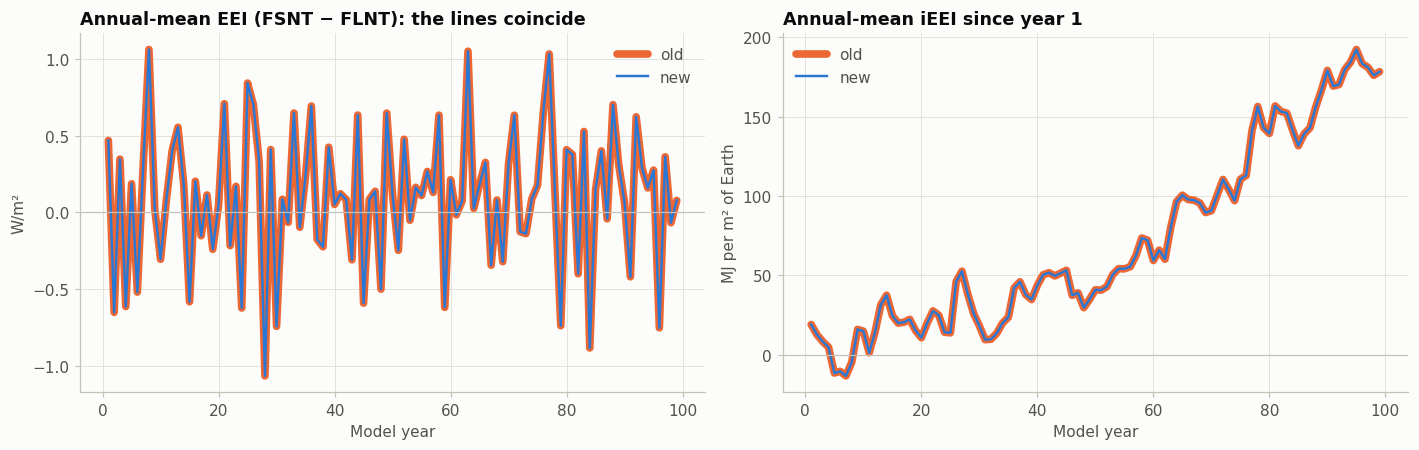

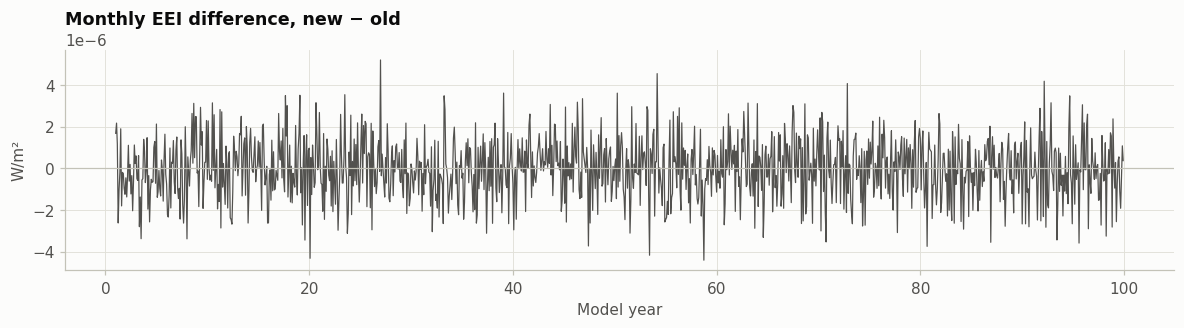

In [4]:
seconds = old_eei_c["time"].dt.days_in_month * 86400.0
old_ieei_c = (old_eei_c * seconds).cumsum("time")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ann_old, ann_new = old_eei_c.groupby("time.year").mean(), new_eei_c.groupby("time.year").mean()
ax1.plot(ann_old["year"], ann_old, color=OLD, lw=5, label="old", solid_capstyle="round")
ax1.plot(ann_new["year"], ann_new, color=NEW, lw=1.6, label="new")
ax1.axhline(0, color=AXIS, lw=0.8)
ax1.set(xlabel="Model year", ylabel="W/m²", title="Annual-mean EEI (FSNT − FLNT): the lines coincide")
ax1.legend(loc="upper right")

ann_old_i, ann_new_i = old_ieei_c.groupby("time.year").mean(), new_ieei_c.groupby("time.year").mean()
ax2.plot(ann_old_i["year"], ann_old_i / 1e6, color=OLD, lw=5, label="old", solid_capstyle="round")
ax2.plot(ann_new_i["year"], ann_new_i / 1e6, color=NEW, lw=1.6, label="new")
ax2.axhline(0, color=AXIS, lw=0.8)
ax2.set(xlabel="Model year", ylabel="MJ per m² of Earth", title="Annual-mean iEEI since year 1")
ax2.legend(loc="upper left")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.plot(year_frac(new_eei_c), new_eei_c - old_eei_c, color=INK2, lw=0.8)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel="Model year", ylabel="W/m²", title="Monthly EEI difference, new − old")
plt.show()

## 3. Ocean heat content by depth bin

Both products report `OHC_global_mean` in J per m² of **ocean** on the same POP grid (identical `ocean_area_m2`).
Absolute OHC depends on the density × heat-capacity constant, so absolute values are compared as a ratio, and the
physically meaningful part — the change since year 1 — is compared directly.

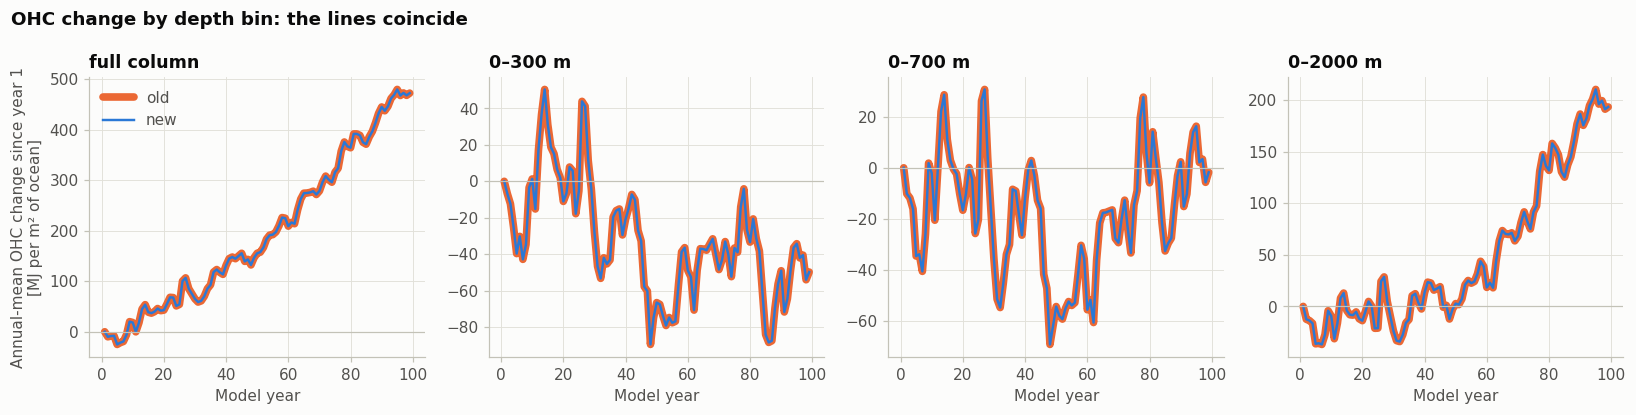

,"new / old, mean","new / old, min","new / old, max"
full column,1.0000254,1.0000254,1.0000254
0–300 m,1.0000254,1.0000254,1.0000254
0–700 m,1.0000254,1.0000254,1.0000254
0–2000 m,1.0000254,1.0000254,1.0000254


New rho*cp = 1026.026 * 3996 = 4.100000e+06 J m-3 K-1
Implied old rho*cp = new / mean ratio = 4.099896e+06  (1026 * 3996 = 4.099896e+06)


In [5]:
depth_names = {-1: "full column", 300: "0–300 m", 700: "0–700 m", 2000: "0–2000 m"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
for ax, d in zip(axes, old_ohc_c["ohc_depth"].values):
    o = old_ohc_c.sel(ohc_depth=d).groupby("time.year").mean()
    n = new_ohc_c.sel(ohc_depth=d).groupby("time.year").mean()
    ax.plot(o["year"], (o - o[0]) / 1e6, color=OLD, lw=5, label="old", solid_capstyle="round")
    ax.plot(n["year"], (n - n[0]) / 1e6, color=NEW, lw=1.6, label="new")
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set(title=depth_names[int(d)], xlabel="Model year")
axes[0].set_ylabel("Annual-mean OHC change since year 1\n[MJ per m² of ocean]")
axes[0].legend(loc="upper left")
fig.suptitle("OHC change by depth bin: the lines coincide", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

ratio = (new_ohc_c / old_ohc_c)
display(pd.DataFrame({
    "new / old, mean": ratio.mean("time").values,
    "new / old, min": ratio.min("time").values,
    "new / old, max": ratio.max("time").values,
}, index=[depth_names[int(d)] for d in ratio["ohc_depth"].values]).style.format("{:.7f}"))
rho_cp_new = newOHC.attrs["rho_kg_m3"] * newOHC.attrs["cp_j_kg_k"]
print(f"New rho*cp = {newOHC.attrs['rho_kg_m3']:.3f} * {newOHC.attrs['cp_j_kg_k']:.0f} = {rho_cp_new:.6e} J m-3 K-1")
print(f"Implied old rho*cp = new / mean ratio = {rho_cp_new / float(ratio.mean()):.6e}"
      f"  (1026 * 3996 = {1026 * 3996:.6e})")

## 4. Summary

In [6]:
sec_total = float(seconds.sum())
rows = []  # old/new columns: EEI mean, otherwise the value at the end of the common period
rows.append(("EEI, month-length-weighted mean (W/m²)", float((old_eei_c * seconds).sum()) / sec_total,
             float((new_eei_c * seconds).sum()) / sec_total, float(np.abs(new_eei_c - old_eei_c).max())))
rows.append(("iEEI at end of common period (J/m² of Earth)", float(old_ieei_c[-1]), float(new_ieei_c[-1]),
             float(np.abs(new_ieei_c - old_ieei_c).max())))
for d in new_ohc_c["ohc_depth"].values:
    o, n = old_ohc_c.sel(ohc_depth=d), new_ohc_c.sel(ohc_depth=d)
    do, dn = o - o[0], n - n[0]
    rows.append((f"OHC change, {depth_names[int(d)]} (J/m² of ocean)", float(do[-1]), float(dn[-1]),
                 float(np.abs(dn - do).max())))
summary = pd.DataFrame(rows, columns=["quantity", "old", "new", "max |new − old|"]).set_index("quantity")
summary["max |new − old| / |old|"] = summary["max |new − old|"] / summary["old"].abs()
display(summary.style.format({"old": "{:.5g}", "new": "{:.5g}", "max |new − old|": "{:.3g}",
                              "max |new − old| / |old|": "{:.2e}"}))

,old,new,max |new − old|,max |new − old| / |old|
quantity,,,,
"EEI, month-length-weighted mean (W/m²)",0.053197,0.053197,5.2e-06,9.77e-05
iEEI at end of common period (J/m² of Earth),1.6608e+08,1.6608e+08,100,6.02e-07
"OHC change, full column (J/m² of ocean)",4.5324e+08,4.5325e+08,1.41e+04,3.12e-05
"OHC change, 0–300 m (J/m² of ocean)",-7.2285e+07,-7.2286e+07,5.17e+03,7.16e-05
"OHC change, 0–700 m (J/m² of ocean)",-2.061e+07,-2.061e+07,4.44e+03,2.15e-04
"OHC change, 0–2000 m (J/m² of ocean)",1.7141e+08,1.7141e+08,7.27e+03,4.24e-05


**Result.** Once the old atmosphere's raw CESM time stamps are shifted back one month, both products describe the
same 1188 months (Jan yr 1 – Dec yr 99; the new products' year 100 is clipped off), and the data confirm that
pairing. Over that period:

- **EEI and iEEI agree to round-off** (monthly differences of order 10⁻⁶ W/m²), so the old and new global means of
  FSNT − FLNT are the same calculation.
- **OHC agrees to a constant factor of 1.000025 at every depth** — the old product used ρ = 1026 kg m⁻³ where the
  rebuild uses POP's exact ρ = 4.1/3.996 × 1000 = 1026.026 kg m⁻³ (both with c_p = 3996 J kg⁻¹ K⁻¹). That changes
  OHC *changes* by only 0.0025%, so the heat-content trends of the two products are the same.

So the old and new pipelines are mutually consistent, and the ≈ 2× gap between OHC gain and iEEI is a property of
the model run (see `energy_budget_summary.ipynb`), not of either implementation.

## 5. How much does monthly weighting matter?

Monthly means of unequal-length months need weighting by month length in two places in the OHC vs. iEEI comparison:

- **integrating EEI into iEEI**: iEEI = Σ EEI × (seconds in the month), a flux summed over time;
- **forming annual means** of OHC and of the running iEEI total, which the gap is measured between (annual mean of
  year 1 → annual mean of year 100).

This section uses **only the rebuilt products** (years 1–100) and recomputes the gap with four weighting schemes:

| scheme | days given to each month |
|---|---|
| correct | the month's own length (Jan 31, Feb 28, …) — what the rebuild uses |
| equal | 365/12 = 30.42 days for every month |
| following month | the *next* month's length (Jan 28, Feb 31, …, Dec 31) — the error from reading month lengths off CESM's raw end-of-period time stamps without first shifting them back one month |
| previous month | the *preceding* month's length (Jan 31 from Dec, Feb 31 from Jan, Mar 28 from Feb, …) — the same one-month slip in the opposite direction |

Each incorrect scheme is applied to one quantity at a time, with the other left correct, to see which errors
matter and by how much.

In [7]:
# WEIGHTING_SENSITIVITY
from ieei import CAM_EARTH_RADIUS_M

EARTH_AREA = 4 * np.pi * CAM_EARTH_RADIUS_M**2
ZJ = 1e21
MONTH_DAYS = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], dtype=float)
SCHEME_DAYS = {  # days given to calendar months Jan..Dec
    "correct": MONTH_DAYS,
    "equal": np.full(12, 365 / 12),
    "following month": np.roll(MONTH_DAYS, -1),  # Jan gets Feb's 28, ..., Dec gets Jan's 31
    "previous month": np.roll(MONTH_DAYS, 1),  # Jan gets Dec's 31, Feb gets Jan's 31, Mar gets Feb's 28, ...
}


def month_weights(time, scheme):
    return xr.DataArray(SCHEME_DAYS[scheme][time.dt.month.values - 1], coords={"time": time}, dims="time")


def weighted_annual_mean(da, scheme):
    w = month_weights(da["time"], scheme)
    return (da * w).groupby("time.year").sum() / w.groupby("time.year").sum()


def ieei_total_J(eei, scheme):
    return (eei * month_weights(eei["time"], scheme) * 86400.0).cumsum("time") * EARTH_AREA


eei_new = newIEEI.EEI_global_mean
ohc_total_new = newOHC.OHC_global_mean.sel(ohc_depth=-1) * newOHC.attrs["ocean_area_m2"]
assert np.allclose(ieei_total_J(eei_new, "correct"), newIEEI.iEEI_total_joules, rtol=1e-10), \
    "correctly weighted reconstruction doesn't reproduce the pipeline's iEEI"

# Why EEI integration is sensitive: its seasonal cycle is ~18 W/m^2 peak-to-peak around a 0.06 W/m^2 mean,
# so moving a day of weight between months at opposite ends of the cycle shifts the mean rate noticeably.
eei_clim = eei_new.groupby("time.month").mean().values
month_table = pd.DataFrame(SCHEME_DAYS, index=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
month_table.insert(0, "EEI climatology [W/m²]", eei_clim)
for scheme in ("equal", "following month", "previous month"):
    month_table[f"rate bias from {scheme} [W/m²]"] = eei_clim * (month_table[scheme] - month_table["correct"]) / 365
display(month_table.style.format("{:+.4f}", subset=[c for c in month_table if "W/m²" in c])
        .format("{:.2f}", subset=list(SCHEME_DAYS)))
print("Implied bias in the mean EEI rate (sum over months):")
for scheme in ("equal", "following month", "previous month"):
    print(f"  {scheme:16s} {month_table[f'rate bias from {scheme} [W/m²]'].sum():+.4f} W/m²")

,EEI climatology [W/m²],correct,equal,following month,previous month,rate bias from equal [W/m²],rate bias from following month [W/m²],rate bias from previous month [W/m²]
Jan,+5.7892,31.00,30.42,28.00,31.00,-0.0093,-0.0476,+0.0000
Feb,+6.7171,28.00,30.42,31.00,31.00,+0.0445,+0.0552,+0.0552
Mar,+6.2815,31.00,30.42,30.00,28.00,-0.0100,-0.0172,-0.0516
Apr,+3.0208,30.00,30.42,31.00,31.00,+0.0034,+0.0083,+0.0083
May,-2.1516,31.00,30.42,30.00,30.00,+0.0034,+0.0059,+0.0059
Jun,-8.3077,30.00,30.42,31.00,31.00,-0.0095,-0.0228,-0.0228
Jul,-11.4435,31.00,30.42,31.00,30.00,+0.0183,-0.0000,+0.0314
Aug,-8.0931,31.00,30.42,30.00,31.00,+0.0129,+0.0222,-0.0000
Sep,-2.8565,30.00,30.42,31.00,31.00,-0.0033,-0.0078,-0.0078
Oct,+1.9366,31.00,30.42,30.00,30.00,-0.0031,-0.0053,-0.0053


Implied bias in the mean EEI rate (sum over months):
  equal            +0.0444 W/m²
  following month  +0.0044 W/m²
  previous month   +0.0119 W/m²


In [8]:
SPAN_S = (int(eei_new.time.dt.year[-1]) - int(eei_new.time.dt.year[0])) * 365 * 86400.0  # yr-1 mean -> yr-100 mean

scenarios = [  # (name, OHC annual-mean weighting, iEEI weighting)
    ("correct (both)", "correct", "correct"),
    ("iEEI: equal weights", "correct", "equal"),
    ("iEEI: following-month weights", "correct", "following month"),
    ("iEEI: previous-month weights", "correct", "previous month"),
    ("OHC: equal weights", "equal", "correct"),
    ("OHC: following-month weights", "following month", "correct"),
]
rows, cumulative = [], {}
for name, ohc_scheme, ieei_scheme in scenarios:
    ohc_ann = weighted_annual_mean(ohc_total_new, ohc_scheme)
    ieei_ann = weighted_annual_mean(ieei_total_J(eei_new, ieei_scheme), ieei_scheme)
    d_ohc, d_ieei = float(ohc_ann[-1] - ohc_ann[0]), float(ieei_ann[-1] - ieei_ann[0])
    rows.append((name, d_ohc / ZJ, d_ieei / ZJ, (d_ohc - d_ieei) / ZJ, d_ohc / d_ieei))
    cumulative[name] = (ohc_ann - ohc_ann[0], ieei_ann - ieei_ann[0])
gap_table = pd.DataFrame(rows, columns=["scenario", "ΔOHC [ZJ]", "ΔiEEI [ZJ]", "gap ΔOHC − ΔiEEI [ZJ]", "OHC / iEEI"])
gap_table = gap_table.set_index("scenario")
gap_table["gap change [ZJ]"] = gap_table["gap ΔOHC − ΔiEEI [ZJ]"] - gap_table.loc["correct (both)", "gap ΔOHC − ΔiEEI [ZJ]"]
gap_table["gap change [W/m² of Earth]"] = gap_table["gap change [ZJ]"] * ZJ / SPAN_S / EARTH_AREA
gap_table["gap change [% of correct gap]"] = 100 * gap_table["gap change [ZJ]"] / gap_table.loc["correct (both)", "gap ΔOHC − ΔiEEI [ZJ]"]
display(gap_table.style.format({"ΔOHC [ZJ]": "{:.3f}", "ΔiEEI [ZJ]": "{:.3f}", "gap ΔOHC − ΔiEEI [ZJ]": "{:.3f}",
                                "OHC / iEEI": "{:.3f}", "gap change [ZJ]": "{:+.3f}",
                                "gap change [W/m² of Earth]": "{:+.5f}", "gap change [% of correct gap]": "{:+.2f}%"}))

,ΔOHC [ZJ],ΔiEEI [ZJ],gap ΔOHC − ΔiEEI [ZJ],OHC / iEEI,gap change [ZJ],gap change [W/m² of Earth],gap change [% of correct gap]
scenario,,,,,,,
correct (both),171.294,82.522,88.772,2.076,+0.000,+0.00000,+0.00%
iEEI: equal weights,171.294,153.288,18.006,1.117,-70.766,-0.04444,-79.72%
iEEI: following-month weights,171.294,89.497,81.797,1.914,-6.975,-0.00438,-7.86%
iEEI: previous-month weights,171.294,101.595,69.698,1.686,-19.074,-0.01198,-21.49%
OHC: equal weights,171.287,82.522,88.765,2.076,-0.007,-0.00000,-0.01%
OHC: following-month weights,171.293,82.522,88.772,2.076,-0.000,-0.00000,-0.00%


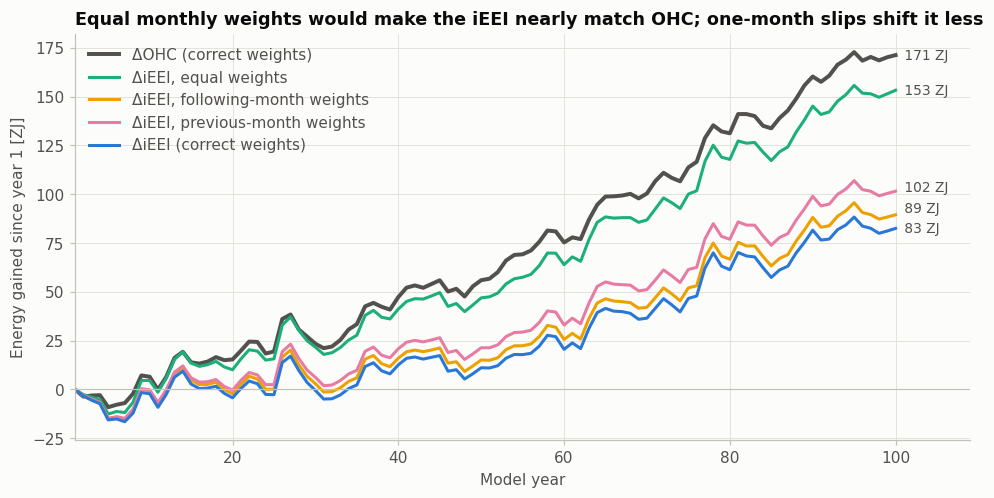

In [9]:
EQUAL, FOLLOWING, PREVIOUS = "#1baf7a", "#eda100", "#e87ba4"
fig, ax = plt.subplots(figsize=(10.5, 4.8))
d_ohc_ann = cumulative["correct (both)"][0] / ZJ
series = [
    ("ΔOHC (correct weights)", d_ohc_ann, INK2, 2.6),
    ("ΔiEEI, equal weights", cumulative["iEEI: equal weights"][1] / ZJ, EQUAL, 2),
    ("ΔiEEI, following-month weights", cumulative["iEEI: following-month weights"][1] / ZJ, FOLLOWING, 2),
    ("ΔiEEI, previous-month weights", cumulative["iEEI: previous-month weights"][1] / ZJ, PREVIOUS, 2),
    ("ΔiEEI (correct weights)", cumulative["correct (both)"][1] / ZJ, NEW, 2),
]
ends = []
for label, s, color, lw in series:
    ax.plot(s["year"], s, color=color, lw=lw, label=label)
    ends.append((float(s[-1]), f" {float(s[-1]):.0f} ZJ"))
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xlim(1, 109)
ymin, ymax = ax.get_ylim()
placed = []
for y, text in sorted(ends):  # nudge end labels apart
    y_text = max(y, placed[-1] + 0.05 * (ymax - ymin)) if placed else y
    placed.append(y_text)
    ax.annotate(text, xy=(100, y), xytext=(100.5, y_text), va="center", color=INK2, fontsize=9)
ax.set(xlabel="Model year", ylabel="Energy gained since year 1 [ZJ]",
       title="Equal monthly weights would make the iEEI nearly match OHC; one-month slips shift it less")
ax.legend(loc="upper left")
plt.show()

**Result.** With correct weights the rebuilt products give ΔOHC = 171 ZJ against ΔiEEI = 83 ZJ over years 1–100,
a gap of ≈ 89 ZJ (ratio 2.08).

- **The iEEI is highly sensitive to weighting.** Giving every month equal weight raises ΔiEEI to ≈ 153 ZJ and
  shrinks the gap by ≈ 71 ZJ (≈ 80%), to a ratio of ≈ 1.1 — an equal-weighting mistake alone would make the
  budget look almost closed. Following-month weights shrink the gap by ≈ 7 ZJ (≈ 8%). The month table shows why:
  EEI swings ≈ 18 W/m² over the year around a mean of only ≈ 0.06 W/m² — positive October–April (largest in
  February, +6.7 W/m²) and negative May–September (lowest in July, −11.4 W/m²). Equal weights add 2.4 days to
  short, high-EEI February and take 0.6 days from each 31-day month, including strongly negative July and August;
  together that biases the mean rate by +0.044 W/m², nearly as large as the 0.057 W/m² imbalance itself.
  Following-month weights move 3 days from January to February, both high-EEI months, so most of that error
  cancels (+0.004 W/m² net).
- **The direction of a one-month slip matters.** Previous-month weights (the same slip the other way) shrink the
  gap by ≈ 19 ZJ (≈ 21%, ratio 1.69) — almost 3× the following-month effect. Both slips give February 3 extra days
  and take them back from a neighbouring high-EEI month (January or March), which largely cancels; the difference is
  elsewhere in the year. Previous-month weights take a day from July, the most negative month (−11.4 W/m²), which
  following-month weights leave alone, for a net bias of +0.012 W/m². Both one-month slips bias the iEEI upward,
  so both make the gap look smaller.
- **The OHC is not sensitive.** Either wrong scheme changes ΔOHC by under 0.01 ZJ. OHC is a state, not a flux:
  a weighting error biases the year-1 and year-100 annual means the same way, so it cancels in their difference,
  leaving only the tiny effect of changes in the shape of the seasonal cycle over the century.

So the ≈ 2× gap is not a weighting artifact of the rebuild — the rebuild weights correctly, and every weighting
error tested here would make the gap *smaller*, not explain it. Any
implementation that integrates EEI without month-length weights (or with weights taken from unshifted CESM time
stamps) would understate the gap, which is worth checking in any other iEEI product this gets compared against.